# Predicting the winner at different stages of the game using Decision Trees

## Question: 
Can we predict the winner of a game at different stages using Decision Trees? These stages include before the game starts, after 10 moves, 20 moves, etc.

## Analysis Plan:
1. Load the dataset and perform initial exploration.
2. Train the Decision Tree model on the available features.
3. Evaluate the model's performance using accuracy, confusion matrix, and classification report.
4. Repeat the step for different stages of the game to see how the model's performance changes.
5. Visualize the difference between the stages

In [519]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_recall_curve,
    average_precision_score
)


Firstly, lets load the dataset

In [520]:
data = pd.read_csv('../Resources/games_data.csv', index_col=0)

print(data["winner"].value_counts())
print(data["winner"].value_counts(normalize=True) * 100)

winner
white    10001
black     9107
draw       950
Name: count, dtype: int64
winner
white    49.860405
black    45.403330
draw      4.736265
Name: proportion, dtype: float64


## Selecting our initial features and target variable
We will start by selecting the features that are available before the game starts. These features include: 
- Player 1's rating
- Player 2's rating
- The opening plies

We can also include some features based on rating differences, to see how they compare to the individual ratings.

In [521]:
data = data[data["winner"] != "draw"]  # Filter out draws

data["rating_diff"] = data["white_rating"] - data["black_rating"]
data["rating_difference_abs"] = data["rating_diff"].abs()
data["rating_average"] = (data["white_rating"] + data["black_rating"]) / 2

features = ["white_rating", "black_rating", "rating_diff", "opening_ply", "rating_difference_abs", "rating_average"]

X = data[features]

y = data["winner"]

## Split the dataset
Separate your dataset into training and testing data. We will use 80% of the data for training and 20% for testing. This will allow us to evaluate the model's performance on unseen data.

In [522]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

We can now create our first Decision Tree model using the training data. After training, we will evaluate the model's performance on the test data.

In [523]:
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

## Evaluate the model's performance
Let's evaluate the model's performance using accuracy, confusion matrix, and classification report. This will give us insights into how well the model is performing and where it might be making mistakes.

As we can see, the model's accuracy is at around 62%. This is a good starting point, but lets see if we can improve the model's performance by now looking at the further stages of the game. We will now look at the model's performance after 10 moves, 20 moves, and so on.

In [524]:
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
macro_f1 = f1_score(y_test, predictions, average="macro")
conf_matrix = confusion_matrix(y_test, predictions)

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print(classification_report(y_test, predictions))
print("Confusion Matrix:\n", conf_matrix)

results = [{
    "moves": "Start",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "confusion_matrix": conf_matrix
}]

Accuracy: 0.6452119309262166
Macro F1: 0.64335208706488
              precision    recall  f1-score   support

       black       0.64      0.60      0.62      1822
       white       0.65      0.69      0.67      2000

    accuracy                           0.65      3822
   macro avg       0.64      0.64      0.64      3822
weighted avg       0.64      0.65      0.64      3822

Confusion Matrix:
 [[1095  727]
 [ 629 1371]]


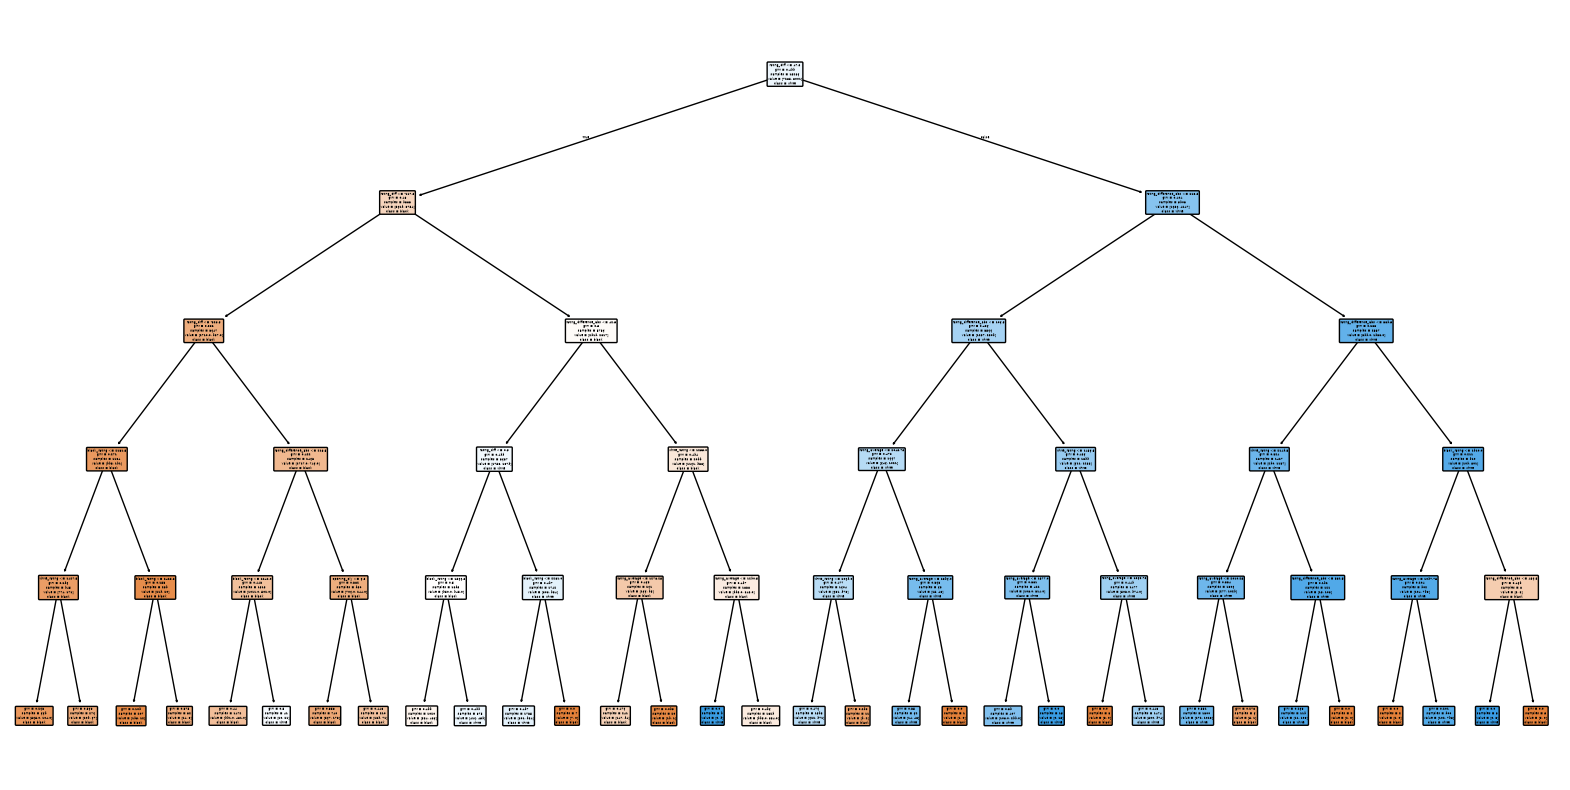

In [525]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.show()

In [526]:
def whites_move(i):
    return i % 2 == 0

"""
Extracts move information from a list of moves.
Calculates the number of captures, checks, promotions, and castling for both white and black players.
"""
def extract_move_information(moves, move_cutoff):
    if move_cutoff == "Start":
        return {
            "white_captures": 0,
            "black_captures": 0,
            "white_checks": 0,
            "black_checks": 0,
            "white_promotions": 0,
            "black_promotions": 0,
            "white_castled": 0,
            "black_castled": 0,
        }
    # Take first `move_cutoff` moves from the moves string
    move_list = moves.split() if move_cutoff is None else moves.split()[:move_cutoff]

    features = {
        "white_captures": 0,
        "black_captures": 0,
        "white_checks": 0,
        "black_checks": 0,
        "white_promotions": 0,
        "black_promotions": 0,
        "white_castled": 0,
        "black_castled": 0,
    }

    
    for i, move in enumerate(move_list):
        # Capture
        if "x" in move:
            if whites_move(i):  # White's move
                features["white_captures"] += 1
            else:  # Black's move
                features["black_captures"] += 1
        # Check
        if "+" in move:
            if whites_move(i):
                features["white_checks"] += 1
            else:  # Black's move
                features["black_checks"] += 1
        # Promotion
        if "=" in move:
            if whites_move(i):
                features["white_promotions"] += 1
            else:  # Black's move
                features["black_promotions"] += 1
        # Castled
        if "O-O" in move or "O-O-O" in move:
            if whites_move(i):
                features["white_castled"] = 1
            else:  # Black's move
                features["black_castled"] = 1
    return features

In [527]:

def decision_tree_model_after_N_moves(data_after_N_moves, y, model_class):
    X_train, X_test, y_train, y_test = train_test_split(data_after_N_moves, y, test_size=0.2, random_state=42, stratify=y)

    model = model_class(
        max_depth=5,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average="macro")
    confusion = confusion_matrix(y_test, predictions)
    return accuracy, f1, confusion

In [528]:
steps = [10, 20, 40, 60, 80, None]  # None is a placeholder for all moves

for step in steps:
    data_after_x_moves = data.copy()

    addtional_features = pd.DataFrame(
        data_after_x_moves["moves"].apply(lambda x: extract_move_information(x, step))
        .tolist(), index=data_after_x_moves.index
    )
    y = data_after_x_moves["winner"]
    data_after_x_moves = pd.concat([data_after_x_moves[features], addtional_features], axis=1)

    accuracy, f1, conf_matrix = decision_tree_model_after_N_moves(
        data_after_x_moves, y, DecisionTreeClassifier
    )   

    results.append({
        "moves": "All" if step == None else step,
        "accuracy": accuracy,
        "macro_f1": f1,
        "confusion_matrix": conf_matrix
    })

results_df = pd.DataFrame(results)

print(results_df)


   moves  accuracy  macro_f1            confusion_matrix
0  Start  0.645212  0.643352  [[1095, 727], [629, 1371]]
1     10  0.646520  0.644760  [[1101, 721], [630, 1370]]
2     20  0.649922  0.645434  [[1027, 795], [543, 1457]]
3     40  0.683673  0.679247  [[1082, 740], [469, 1531]]
4     60  0.710361  0.708329  [[1198, 624], [483, 1517]]
5     80  0.731554  0.731530  [[1380, 442], [584, 1416]]
6    All  0.735217  0.735147  [[1374, 448], [564, 1436]]


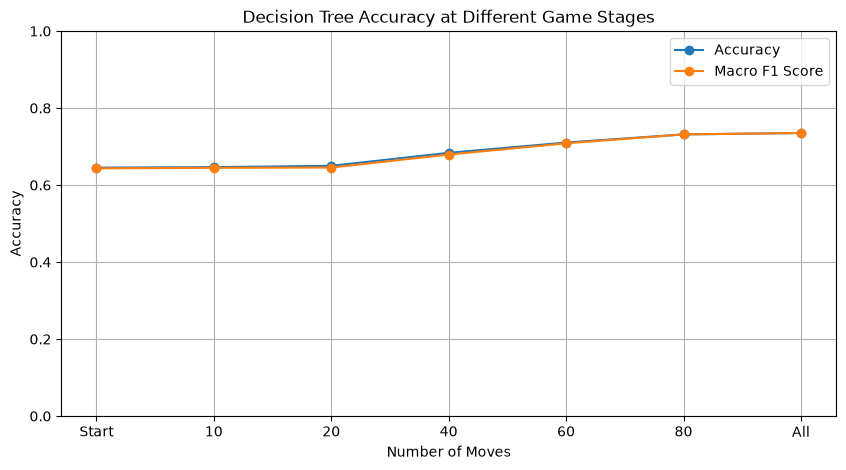

In [529]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["moves"].astype(str),
    results_df["accuracy"],
    marker="o",
    label="Accuracy"
)
plt.plot(
    results_df["moves"].astype(str),
    results_df["macro_f1"],
    marker="o",
    label="Macro F1 Score"
)
plt.title("Decision Tree Accuracy at Different Game Stages")
plt.xlabel("Number of Moves")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.show()


Lets uh try a random forest now ig bruh. 

In [530]:
results_forest = []
steps = ["Start", 10, 20, 40, 60, 80, None]  # None is a placeholder for all moves

for step in steps:
    data_after_x_moves = data.copy()

    addtional_features = pd.DataFrame(
        data_after_x_moves["moves"].apply(lambda x: extract_move_information(x, step))
        .tolist(), index=data_after_x_moves.index
    )
    y = data_after_x_moves["winner"]
    data_after_x_moves = pd.concat([data_after_x_moves[features], addtional_features], axis=1)

    accuracy, f1, conf_matrix = decision_tree_model_after_N_moves(
        data_after_x_moves, y, RandomForestClassifier
    )   

    results_forest.append({
        "moves": "All" if step == None else step,
        "accuracy": accuracy,
        "macro_f1": f1,
        "confusion_matrix": conf_matrix
    })

results_df_forest = pd.DataFrame(results_forest)

print(results_df_forest)

   moves  accuracy  macro_f1            confusion_matrix
0  Start  0.649922  0.645434  [[1027, 795], [543, 1457]]
1     10  0.652800  0.649497  [[1062, 760], [567, 1433]]
2     20  0.649660  0.647444  [[1090, 732], [607, 1393]]
3     40  0.696494  0.693716  [[1149, 673], [487, 1513]]
4     60  0.731293  0.728764  [[1213, 609], [418, 1582]]
5     80  0.753532  0.751900  [[1285, 537], [405, 1595]]
6    All  0.771847  0.770297  [[1318, 504], [368, 1632]]


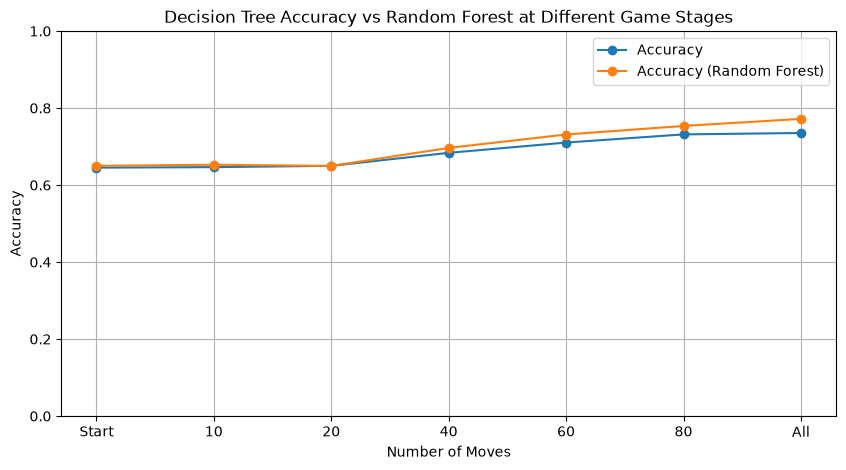

In [532]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["moves"].astype(str),
    results_df["accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df_forest["moves"].astype(str),
    results_df_forest["accuracy"],
    marker="o",
    label="Accuracy (Random Forest)"
)


plt.title("Decision Tree Accuracy vs Random Forest at Different Game Stages")
plt.xlabel("Number of Moves")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.show()